In [1]:
import sympy as sp
import numpy as np
import scipy
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from sympy import  symbols, sin , cos, lambdify, atan, acos, nsolve
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

### Cinematica directa

In [ ]:
t = symbols('t')
theta2, theta3, x, theta1 = symbols('theta2, theta3, x, theta1')

t_ = np.linspace(0, 5, 100)

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = A.orientnew('B', 'Axis', (N.z, -theta2))
C = B.orientnew('C', 'Axis', (N.z, -theta3))

eq = 0.2*A.x + 0.15*B.x + 0.6*C.x - 0.05*N.y - x*N.x

pos = lambdify([theta1, theta2, theta3, x], [eq.dot(N.x), eq.dot(N.y)])

theta_1 = list(np.deg2rad(67.5 + 7.5*np.sin(5*t_)))
x_1 = list((70 + 5*np.sin(5*t_))/100)

theta_2, theta_3 = [], []

for i in range(len(theta_1)):
    fsolve_fun = lambda z: pos(theta_1[i], z[0], z[1], x_1[i])
    out = fsolve(fsolve_fun, [0.56, 0.050], full_output = True)
    theta_2.append(list(out[0])[0])
    theta_3.append(list(out[0])[1])

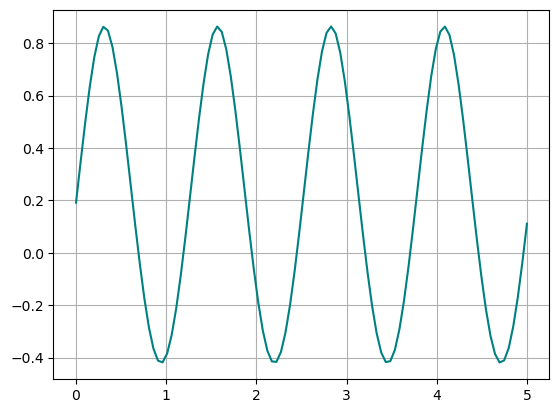

In [3]:
plt.plot(t_, theta_2, color = 'teal')
plt.grid(True)

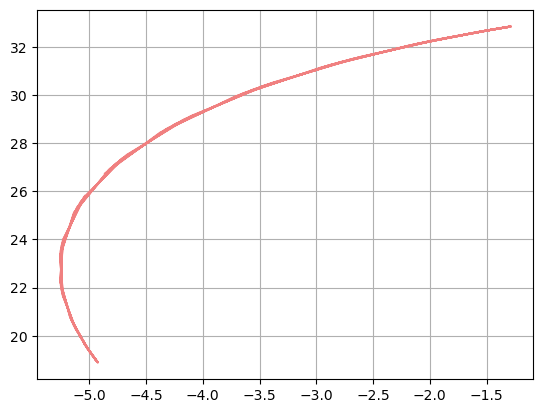

In [4]:
eq2 = 20*A.x + 15*B.y 
S_pos = [eq2.dot(N.x), eq2.dot(N.y)]

x_S, y_S = [], []

for v in range(len(t_)):
    x_v = S_pos[0].subs({theta1: theta_1[v], theta2: theta_2[v]})
    y_v = S_pos[1].subs({theta1: theta_1[v], theta2: theta_2[v]})
        
    x_S.append(x_v)
    y_S.append(y_v)

plt.plot(x_S, y_S, color='lightcoral')
plt.grid(True)

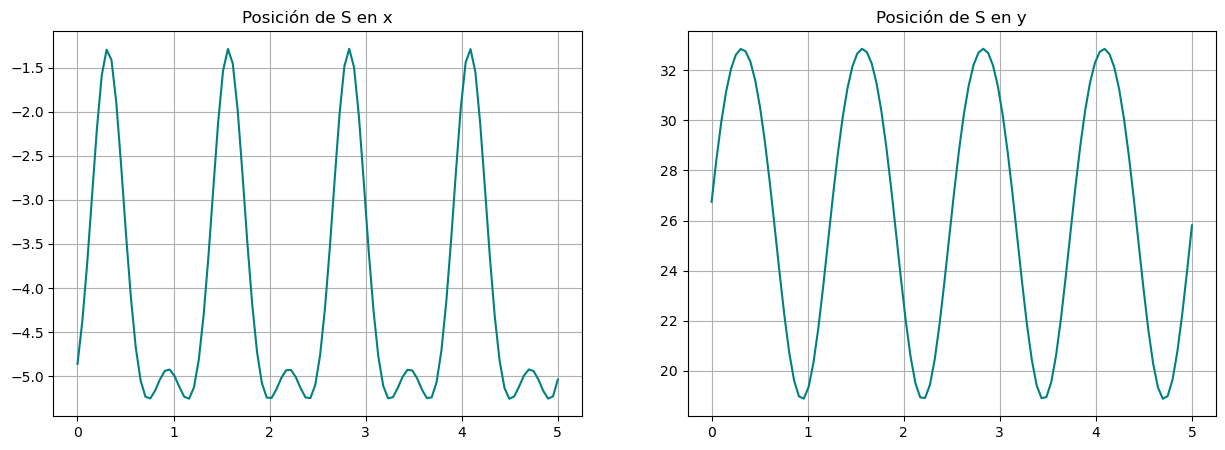

In [5]:
plt.figure(figsize=(15, 5))
plt.subplot(121)
plt.title('Posición de S en x')
plt.plot(t_, x_S, color = 'teal')
plt.grid(True)

plt.subplot(122)
plt.title('Posición de S en y')
plt.plot(t_, y_S, color = 'teal')
plt.grid(True)

### Cinematica inversa

In [ ]:
c_pos = []

p = 100
for i in range(p):
        c_pos.append([2 + 2*np.cos(i*(2*np.pi/p)), 30 + 2*np.sin(i*(2*np.pi/p))])

eq2 = 20*A.x + 15*B.y 
M_Spos = sp.Matrix([eq2.dot(N.x), eq2.dot(N.y)])
pos_fun = lambdify([theta1, theta2], M_Spos)

theta1_inv, theta2_inv = [], []

def error_fun(q):
        er = pos - pos_fun(q[0], q[1])
        return np.square(er).sum()

for pos in c_pos:
        sln = scipy.optimize.minimize(error_fun, [0.9, 0.60])
        theta1_inv.append(sln.x[0])
        theta2_inv.append(sln.x[1])

pos = lambdify([theta1, theta2, theta3, x], [eq.dot(N.x), eq.dot(N.y)])

theta3_inv, x_inv = [], []

for i in range(len(theta1_inv)):
        fsolve_fun = lambda z: pos(theta1_inv[i], theta2_inv[i], z[0], z[1])
        out = fsolve(fsolve_fun, [0.55, 0.98], full_output = True)
        theta3_inv.append(list(out[0])[0])
        x_inv.append(list(out[0])[1])

In [7]:
c_pos

[[4.0, 30.0],
 [3.996053456856543, 30.125581039058627],
 [3.984229402628956, 30.25066646712861],
 [3.9645745014573777, 30.37476262917145],
 [3.937166322257262, 30.49737977432971],
 [3.9021130325903073, 30.618033988749893],
 [3.8595529717765027, 30.736249105369357],
 [3.809654104932039, 30.851558583130146],
 [3.752613360087727, 30.963507348203432],
 [3.68865585100403, 31.071653589957993],
 [3.618033988749895, 31.175570504584947],
 [3.541026485551578, 31.27484797949738],
 [3.457937254842823, 31.369094211857377],
 [3.3690942118573775, 31.45793725484282],
 [3.2748479794973795, 31.54102648555158],
 [3.175570504584946, 31.618033988749893],
 [3.071653589957993, 31.68865585100403],
 [2.9635073482034304, 31.75261336008773],
 [2.8515585831301453, 31.80965410493204],
 [2.736249105369356, 31.859552971776502],
 [2.618033988749895, 31.902113032590307],
 [2.4973797743297093, 31.937166322257262],
 [2.374762629171449, 31.964574501457378],
 [2.2506664671286085, 31.984229402628955],
 [2.1255810390586265,